# Лабораторна робота №2. Зниження розмірності, кластеризація та обробка текстів

У частинах 1 і 2 використано той самий датасет, що в лабораторній роботі №1 (Phishing Dataset for Machine Learning, Kaggle), https://www.kaggle.com/datasets/shashwatwork/phishing-dataset-for-machine-learning. У частині 3 класифікуємо тексти SMS.

In [1]:
import time
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.svm import SVC
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, silhouette_score, adjusted_rand_score
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.linear_model import LogisticRegression
from wordcloud import WordCloud

## Підготовка даних (як у лабораторній роботі №1)

In [2]:
df = pd.read_csv('../../data/phishing_ml/Phishing_Legitimate_full.csv')
df = df.drop('id', axis=1)  # id це номер рядка
df = df.drop_duplicates()  # дублікати прибираємо до розбиття
X = df.drop('CLASS_LABEL', axis=1)
y = df['CLASS_LABEL']
X.shape

(9581, 48)

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)  # fit лише на train
X_test_scaled = scaler.transform(X_test)

Усі три методи цієї роботи (PCA, t-SNE і K-Means) працюють з відстанями та дисперсіями, тому ознаки з великими числами (наприклад довжина URL) без масштабування домінували б над рештою. Тут дані ті самі, що в лабораторній роботі №1, з очищенням і розбиттям 80 на 20.

## 1. Зниження розмірності та візуалізація

### 1.1 PCA

In [4]:
pca = PCA(n_components=0.95)  # лишаємо стільки компонент, щоб пояснити 95% дисперсії
X_train_pca = pca.fit_transform(X_train_scaled)  # fit лише на train
X_test_pca = pca.transform(X_test_scaled)
X_train_scaled.shape[1], int(pca.n_components_)

(48, 34)

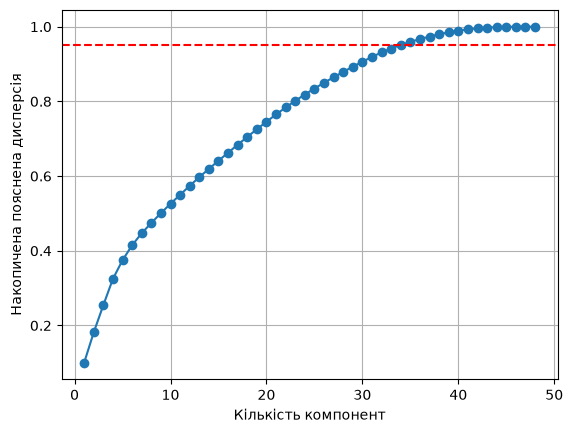

In [5]:
pca_full = PCA().fit(X_train_scaled)  # усі компоненти, лише для графіка
plt.plot(range(1, 49), np.cumsum(pca_full.explained_variance_ratio_), marker='o')
plt.axhline(0.95, color='red', linestyle='--')
plt.xlabel('Кількість компонент')
plt.ylabel('Накопичена пояснена дисперсія')
plt.grid()
plt.show()

Для пояснення 95% дисперсії вистачило 34 компонент з 48, тобто ознак стало на 29% менше. Крива зростає поступово, різкого перегину немає, бо ознаки пов'язані між собою лише частково.

Для порівняння візьмемо SVM з найкращими параметрами з лабораторної роботи №1 (C=10, gamma='scale'). Він працює з відстанями, тому дані після PCA (теж масштабовані) йому підходять, а час навчання у нього помітний, тож різницю буде видно.

In [6]:
start = time.time()
svm_before = SVC(C=10, gamma='scale', random_state=42)
svm_before.fit(X_train_scaled, y_train)
time_before = time.time() - start
pred_before = svm_before.predict(X_test_scaled)
print(classification_report(y_test, pred_before))

              precision    recall  f1-score   support

           0       0.98      0.97      0.98      1000
           1       0.97      0.97      0.97       917

    accuracy                           0.97      1917
   macro avg       0.97      0.97      0.97      1917
weighted avg       0.97      0.97      0.97      1917



In [7]:
start = time.time()
svm_after = SVC(C=10, gamma='scale', random_state=42)
svm_after.fit(X_train_pca, y_train)
time_after = time.time() - start
pred_after = svm_after.predict(X_test_pca)
print(classification_report(y_test, pred_after))

              precision    recall  f1-score   support

           0       0.97      0.96      0.97      1000
           1       0.96      0.97      0.96       917

    accuracy                           0.97      1917
   macro avg       0.97      0.97      0.97      1917
weighted avg       0.97      0.97      0.97      1917



In [8]:
pd.DataFrame({
    'варіант': ['до PCA', 'після PCA'],
    'ознак': [X_train_scaled.shape[1], X_train_pca.shape[1]],
    'accuracy': [accuracy_score(y_test, pred_before), accuracy_score(y_test, pred_after)],
    'час навчання, с': [time_before, time_after]}).round(4)

,варіант,ознак,accuracy,"час навчання, с"
0,до PCA,48,0.9744,0.3757
1,після PCA,34,0.9656,0.3443


Якість трохи впала, accuracy 0,9744 до PCA і 0,9656 після (на 0,9 п.п., приблизно на 17 об'єктів тесту більше помилок). Ознак стало 34 замість 48, але час навчання майже не змінився (0,38 с проти 0,34 с). SVM на 7664 об'єктах навчається і так швидко, а зменшення з 48 до 34 ознак на цьому розмірі нічого суттєвого не дає. Тому для цих даних PCA не покращує класифікацію, бо відкинуті 5% дисперсії містять частину корисної для класу інформації.

### 1.2 t-SNE

In [9]:
X_all_scaled = StandardScaler().fit_transform(X)  # усі 9581 рядків, масштабовані
start = time.time()
X_tsne = TSNE(n_components=2, random_state=42).fit_transform(X_all_scaled)
print('час t-SNE, с', round(time.time() - start, 1))

час t-SNE, с 19.0


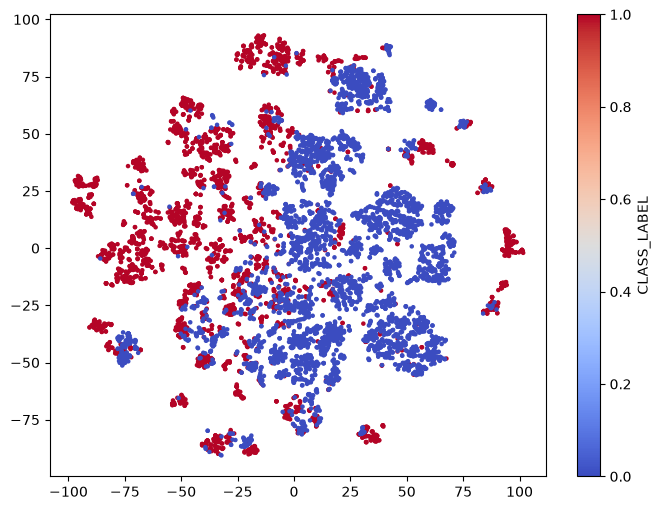

In [10]:
plt.figure(figsize=(8, 6))
plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=y, cmap='coolwarm', s=5)
plt.colorbar(label='CLASS_LABEL')
plt.show()

Використано всі 9581 рядків, t-SNE працював близько 19 с, тому підвибірка не потрібна. Класи утворюють багато компактних груп. Фішингові сайти (червоні) в основному зібрані зліва і по краях, легітимні (сині) справа, тобто класи в просторі ознак справді розділяються. У середині діаграми групи перемішані, там і виникають помилки класифікаторів. t-SNE зберігає лише близькість сусідніх точок, тому відстані між групами і їхній розмір інтерпретувати не можна.

## 2. Кластерний аналіз (K-Means)

Мітки класів у кластеризації не використовуємо, K-Means отримує лише масштабовані ознаки. Їх беремо з усіх 9581 рядків (X_all_scaled), бо навчального і тестового поділу тут не потрібно.

In [11]:
inertia = []
silhouette = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(X_all_scaled)
    inertia.append(km.inertia_)
    silhouette.append(silhouette_score(X_all_scaled, labels))
pd.DataFrame({'k': range(2, 11), 'inertia': inertia, 'silhouette': silhouette}).round(4)

,k,inertia,silhouette
0,2,421072.0475,0.1305
1,3,397508.5865,0.0883
2,4,375554.0110,0.1116
3,5,353783.2266,0.1098
4,6,339249.4444,0.1192
5,7,330425.3183,0.1224
6,8,316522.9612,0.1278
7,9,310350.0987,0.1211
8,10,296822.7734,0.1283


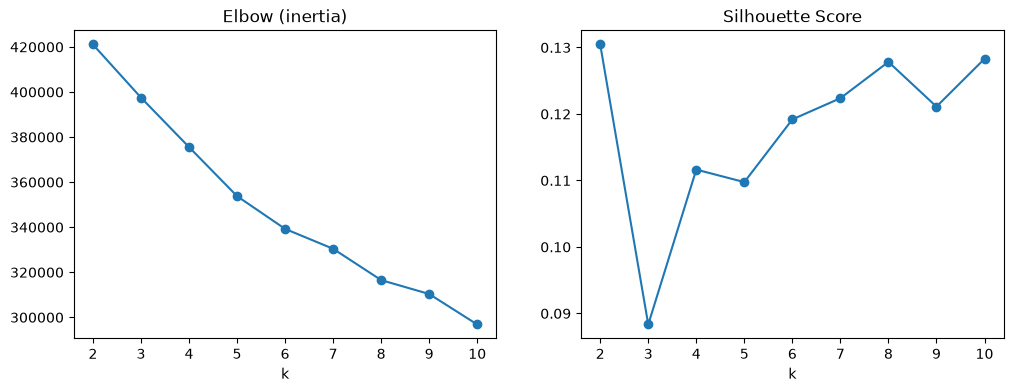

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(range(2, 11), inertia, marker='o')
axes[0].set_title('Elbow (inertia)')
axes[0].set_xlabel('k')
axes[1].plot(range(2, 11), silhouette, marker='o')
axes[1].set_title('Silhouette Score')
axes[1].set_xlabel('k')
plt.show()

Крива inertia спадає плавно, чіткого ліктя немає. Silhouette найбільший при k=2 (0,1305), далі найкраще k=10 (0,1283), а мінімум при k=3 (0,0883). Обираємо k=2. Значення silhouette при цьому дуже мале (поблизу 0,13, тоді як чіткій структурі відповідають значення ближче до 1), тобто кластери виражені слабко.

In [13]:
kmeans = KMeans(n_clusters=2, n_init=10, random_state=42)
clusters = kmeans.fit_predict(X_all_scaled)

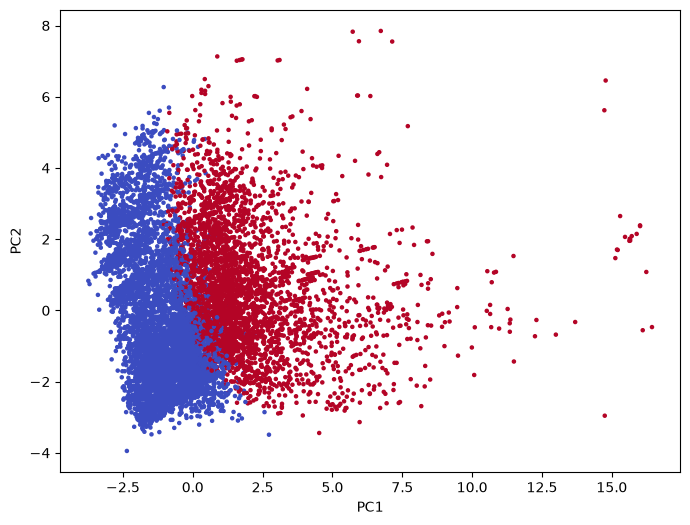

In [14]:
X_pca2 = PCA(n_components=2).fit_transform(X_all_scaled)  # 2D лише для малюнка
plt.figure(figsize=(8, 6))
plt.scatter(X_pca2[:, 0], X_pca2[:, 1], c=clusters, cmap='coolwarm', s=5)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.show()

Кластери розділені приблизно вздовж PC1 і межа між ними проходить усередині суцільної хмари точок, тож чіткого розриву між групами немає.

In [15]:
pd.crosstab(clusters, y)

CLASS_LABEL,0,1
row_0,,
0,2646,3552
1,2350,1033


In [16]:
adjusted_rand_score(y, clusters)

0.053593637968514324

Кластер 0 містить 2646 легітимних і 3552 фішингових сайтів, кластер 1 містить 2350 легітимних і 1033 фішингових. Кластер 1 більше легітимний (69%), кластер 0 більше фішинговий (57%), але перемішування велике. Adjusted Rand Index дорівнює 0,0536, тобто майже 0 (випадкове розбиття), тому знайдені кластери реальним класам не відповідають. Це не помилка методу, бо K-Means групує за загальною схожістю всіх 48 ознак (довжина адреси, кількість посилань тощо), а ця схожість не збігається з тим, фішинговий сайт чи ні.

## 3. Обробка та класифікація текстів

Датасет SMS Spam Collection (UCI), https://archive.ics.uci.edu/dataset/228/sms+spam+collection. Це англомовні SMS, які позначені як ham (звичайне) або spam.

In [17]:
sms = pd.read_csv('../../data/sms_spam/spam.csv', encoding='latin-1')
sms = sms[['v1', 'v2']]  # решта стовпців порожні
sms.columns = ['label', 'text']
sms.shape

(5572, 2)

In [18]:
sms['label'].value_counts()

label
ham     4825
spam     747
Name: count, dtype: int64

In [19]:
sms.duplicated().sum()

np.int64(403)

У наборі 5572 повідомлення, spam лише 747 (13%), а 403 повідомлення є повними дублікатами. Їх видаляємо до розбиття, інакше однакове повідомлення потрапить і в train, і в test, а оцінка буде завищеною. Після видалення лишилося 5169 повідомлень (4516 ham і 653 spam).

In [20]:
sms = sms.drop_duplicates()  # до розбиття, щоб копії не потрапили і в train, і в test
sms['label'].value_counts()

label
ham     4516
spam     653
Name: count, dtype: int64

### 3.1 Передобробка

In [21]:
def clean(text):
    text = text.lower()
    text = re.sub(r'[^a-z\s]', ' ', text)  # прибираємо пунктуацію і цифри
    words = [w for w in text.split() if w not in ENGLISH_STOP_WORDS and len(w) > 1]  # прибираємо стоп-слова і одиночні літери
    return ' '.join(words)

In [22]:
sms['clean'] = sms['text'].apply(clean)
sms[['text', 'clean']].head()

,text,clean
0,"Go until jurong point, crazy.. Available only ...",jurong point crazy available bugis great world...
1,Ok lar... Joking wif u oni...,ok lar joking wif oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry wkly comp win fa cup final tkts st ...
3,U dun say so early hor... U c already then say...,dun say early hor say
4,"Nah I don't think he goes to usf, he lives aro...",nah don think goes usf lives


Стоп-слова (the, is, you та подібні) є в усіх текстах і майже нічого не говорять про клас, тому їх прибрано разом із пунктуацією та цифрами.

### 3.2 WordCloud

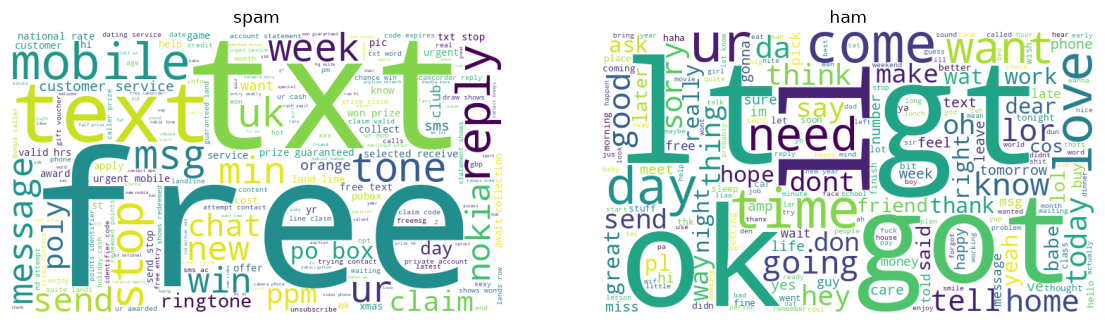

In [23]:
spam_text = ' '.join(sms[sms['label'] == 'spam']['clean'])
ham_text = ' '.join(sms[sms['label'] == 'ham']['clean'])
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].imshow(WordCloud(width=700, height=400, background_color='white').generate(spam_text))
axes[0].set_title('spam')
axes[1].imshow(WordCloud(width=700, height=400, background_color='white').generate(ham_text))
axes[1].set_title('ham')
axes[0].axis('off')
axes[1].axis('off')
plt.show()

У spam найвиразніші слова free, txt, text, mobile, claim, prize, stop, reply, win, тобто заклики щось отримати безкоштовно або відповісти на повідомлення. У ham слова повсякденного спілкування, ok, got, come, love, day, time, need. Слова lt і gt це залишки HTML-кодів знаків < і > з тексту повідомлень, до змісту вони не стосуються.

### 3.3 Векторизація і класифікація

In [24]:
X_text = sms['clean']
y_text = sms['label']
Xt_train, Xt_test, yt_train, yt_test = train_test_split(X_text, y_text, test_size=0.2, stratify=y_text, random_state=42)

In [25]:
tfidf = TfidfVectorizer()
Xt_train_vec = tfidf.fit_transform(Xt_train)  # словник будуємо лише на train
Xt_test_vec = tfidf.transform(Xt_test)
Xt_train_vec.shape

(4135, 6477)

TF-IDF замінює кожне повідомлення на вектор, у якому кожне слово має вагу. Вага вища для слів, що часто трапляються в цьому повідомленні, але рідко в інших.

In [26]:
model = LogisticRegression(random_state=42)
model.fit(Xt_train_vec, yt_train)
pred_text = model.predict(Xt_test_vec)

In [27]:
print(classification_report(yt_test, pred_text))

              precision    recall  f1-score   support

         ham       0.95      1.00      0.98       903
        spam       0.99      0.67      0.80       131

    accuracy                           0.96      1034
   macro avg       0.97      0.84      0.89      1034
weighted avg       0.96      0.96      0.95      1034



In [28]:
confusion_matrix(yt_test, pred_text, labels=['ham', 'spam'])

array([[902,   1],
       [ 43,  88]])

Accuracy дорівнює 0,96, але клас spam рідкісний (131 з 1034 у тесті), тому дивимось на його метрики. Precision spam 0,99 (з 89 повідомлень, названих спамом, помилково лише 1), а recall 0,67 (знайдено 88 зі 131, пропущено 43), f1 для spam 0,80. Тобто модель обережна, майже не хибить на звичайних повідомленнях, але пропускає третину спаму, тому одна лише accuracy картину завищує.

## Висновок

PCA залишив 34 компоненти з 48 (95% дисперсії), SVM після цього втратив близько 0,9 п.п. accuracy (0,9744 проти 0,9656) без виграшу за часом, бо дані невеликі. t-SNE показав, що класи фішингових і легітимних сайтів утворюють окремі групи, які частково перемішані. K-Means обрав k=2 за silhouette (0,1305), але кластери слабкі і з реальними класами не збігаються (ARI 0,0536), бо кластер і клас це різні поняття. На SMS логістична регресія з TF-IDF дала accuracy 0,96, а для рідкісного класу spam precision 0,99 і recall 0,67, тобто частину спаму вона пропускає.